# 1. Datos y preprocesamiento

**Pronóstico del consumo eléctrico residencial por distrito con aprendizaje automático** · Sistemas Inteligentes · Grupo 6 · UNMSM

**Objetivo.** Describir los datos abiertos de ENOSA y transformarlos en el panel distrito-mes con el que se entrenan los modelos, sin usar datos personales.

| | |
|---|---|
| **Entradas** | `datos/limpios/enosa_AAAAMM.parquet` (34 meses, solo columnas no personales; se obtienen con `python cli.py descargar`) |
| **Salidas** | `datos/procesados/panel.parquet` y `datos/procesados/preprocesamiento.json` |

### Índice

1. [Configuración](#configuración)
2. [Fuente de los datos](#fuente-de-los-datos)
3. [Variables y datos personales](#variables-y-datos-personales)
4. [Análisis exploratorio](#análisis-exploratorio)
5. [Limpieza y filtrado](#limpieza-y-filtrado)
6. [Valores atípicos: cercas de Tukey](#valores-atípicos-cercas-de-tukey)
7. [Agregación por distrito y mes](#agregación-por-distrito-y-mes)
8. [Variables de entrada y formulaciones](#variables-de-entrada-y-formulaciones)
9. [Verificación con el informe](#verificación-con-el-informe)
10. [Conclusiones](#conclusiones)
11. [Referencias](#referencias)

<a id="configuración"></a>

## 1. Configuración

Importaciones, estilo de los gráficos y resultados publicados del informe, que se usan al final para verificar que el notebook reproduce las mismas cifras.

In [1]:
import json
import warnings

import estilo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from estilo import BLUE, CYAN, EJE_COMA, GRIS, ICE, MESES, NAVY, coma

from ml import config

estilo.aplicar()
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
INFORME = json.loads(config.RESULTADOS.read_text(encoding="utf8"))  # resultados publicados
RESUMEN = json.loads(config.RESUMEN_PREPROCESAMIENTO.read_text(encoding="utf8"))

from ml.config import CONSERVADAS, PERSONALES
from ml.preprocesamiento import RIC_TUKEY, cargar_limpios, construir_panel

<a id="fuente-de-los-datos"></a>

## 2. Fuente de los datos

El conjunto de datos *Consumo energético de clientes Enosa [Distriluz - DLZ]* se publica en la Plataforma Nacional de Datos Abiertos bajo la licencia **ODbL** (ENOSA, 2026). Cada archivo mensual tiene un registro por suministro: ubicación, tarifa, tipo de cliente, fechas del periodo facturado, importe y consumo. Se usan los 34 meses publicados, de enero de 2024 a octubre de 2026.

Los archivos no tienen formato uniforme (CSV, XLSX o ZIP; algunos CSV sin fila de encabezado), por eso el módulo `ml/fuente.py` asigna las columnas por su **posición** en el diccionario de datos. Aquí se parte de los archivos ya leídos y guardados en Parquet.

In [2]:
df = cargar_limpios(config.DIR_LIMPIOS)
por_mes = df.groupby("PERIODO").size()
print(
    f"{coma(len(df))} registros en {por_mes.size} meses ({por_mes.index[0]} a {por_mes.index[-1]})"
)
por_mes.groupby(por_mes.index.str[:4]).agg(
    meses="size", registros="sum", promedio_mensual="mean"
).round(0)

19 713 482 registros en 53 meses ( a S018-07637634)


,meses,registros,promedio_mensual
PERIODO,,,
,1,12,12.0000
11.1,1,1,1.0000
114,1,1,1.0000
202,1,1,1.0000
2023,1,1,1.0000
2024,14,6799024,"485,645.0000"
2025,12,6961778,"580,148.0000"
2026,10,5952612,"595,261.0000"
37,1,1,1.0000


<a id="variables-y-datos-personales"></a>

## 3. Variables y datos personales

El diccionario describe **25 variables**. Las columnas 2 a 6 identifican a la persona (número de suministro, nombre, dirección, tipo y número de documento). Seis meses se publicaron **sin anonimizar**; por eso esas columnas se descartan por posición al leer cada línea y nunca se guardan, en concordancia con la Ley N.° 29733 de Protección de Datos Personales (Congreso de la República del Perú, 2011).

In [3]:
print("Columnas personales (descartadas al leer):", PERSONALES)
print("Columnas conservadas:", len(CONSERVADAS))
assert not set(PERSONALES) & set(df.columns), "ninguna columna personal llega a este notebook"
df.head(3)

Columnas personales (descartadas al leer): ['NRO_SERVICIO', 'NOMBRE_SERVICIO', 'DIRECCION', 'ID_TIPO_IDENTIDAD', 'NRO_IDENTIDAD']
Columnas conservadas: 16


,PERIODO,FECHA_CORTE,ID_UUNN,UNIDAD_NEGOCIO,TARIFA,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,CARTERA,FECHA_EMISION,FECHA_VENCIMIENTO,FECHA_CONSUMO_DESDE,FECHA_CONSUMO_HASTA,IMPORTE,CONSUMO
0,202401,20240131,4,Alto Piura,BT5B,Piura,Morropon,Chulucanas,200401,C,20240129,20240215,20231223,20240123,190.3000,168.0000
1,202401,20240131,4,Alto Piura,BT5B,Piura,Morropon,Chulucanas,200401,C,20240129,20240215,20231223,20240123,12.4000,6.0000
2,202401,20240131,4,Alto Piura,BT5B,Piura,Morropon,Chulucanas,200401,C,20240129,20240215,20231223,20240123,11.4000,13.0000


La verificación confirma que ninguna de las columnas personales está en los datos de trabajo.

<a id="análisis-exploratorio"></a>

## 4. Análisis exploratorio

Se describe el consumo de un recibo residencial con tarifa BT5B (los hogares). Su distribución tiene una **cola larga a la derecha** y muchos recibos en cero, por lo que el análisis trabaja con suministros activos y trata los valores extremos.

mediana 50 kWh · media 93,4 kWh · percentiles 95 y 99: 265 y 806 kWh · recibos en cero: 8,9 %


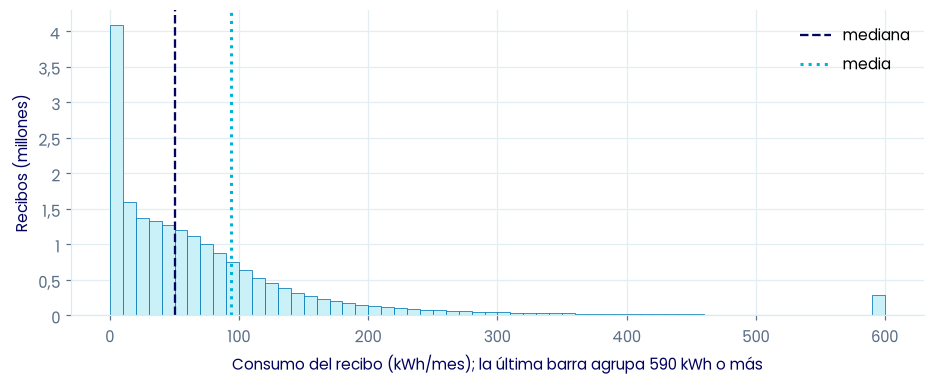

In [4]:
res = df[(df["CARTERA"] == "C") & (df["TARIFA"] == "BT5B")]["CONSUMO"].dropna()
print(
    f"mediana {coma(res.median())} kWh · media {coma(res.mean(), 1)} kWh · "
    f"percentiles 95 y 99: {coma(res.quantile(0.95))} y {coma(res.quantile(0.99))} kWh · "
    f"recibos en cero: {coma((res == 0).mean() * 100, 1)} %"
)
fig, ax = plt.subplots()
ax.hist(
    res.clip(upper=600),
    bins=60,
    range=(0, 600),
    color=ICE,
    edgecolor=BLUE,
    lw=0.5,
    weights=np.full(len(res), 1e-6),
)
ax.axvline(res.median(), color=NAVY, ls="--", label="mediana")
ax.axvline(res.mean(), color=CYAN, ls=":", lw=2, label="media")
ax.set(
    xlabel="Consumo del recibo (kWh/mes); la última barra agrupa 590 kWh o más",
    ylabel="Recibos (millones)",
)
ax.yaxis.set_major_formatter(EJE_COMA)
ax.legend()
plt.show()

La mediana (50 kWh) está muy por debajo de la media (93,2 kWh): unos pocos recibos muy altos arrastran el promedio. Además, cerca del 9 % de los recibos registra consumo cero.

<a id="limpieza-y-filtrado"></a>

## 5. Limpieza y filtrado

Los filtros, en orden:

1. registros con periodo, ubigeo y departamento válidos (Piura o Tumbes);
2. clientes residenciales (cartera común, `C`) con tarifa **BT5B**;
3. consumo no nulo ni negativo y periodo facturado de 20 a 40 días.

La tabla muestra cuántos registros quedan tras cada paso.

In [5]:
ok = (
    df["PERIODO"].str.fullmatch(r"202[4-6](0[1-9]|1[0-2])", na=False)
    & df["UBIGEO"].str.fullmatch(r"(20|24)\d{4}", na=False)
    & df["DEPARTAMENTO"].str.upper().str.strip().isin(["PIURA", "TUMBES"])
)
paso1 = df[ok]
paso2 = paso1[(paso1["CARTERA"] == "C") & (paso1["TARIFA"] == "BT5B")]
dias = (
    pd.to_datetime(paso2["FECHA_CONSUMO_HASTA"], format="%Y%m%d", errors="coerce")
    - pd.to_datetime(paso2["FECHA_CONSUMO_DESDE"], format="%Y%m%d", errors="coerce")
).dt.days
paso3 = paso2[paso2["CONSUMO"].notna() & (paso2["CONSUMO"] >= 0) & dias.between(20, 40)]
pd.DataFrame(
    {"registros": [len(df), len(paso1), len(paso2), len(paso3)]},
    index=[
        "Descargados",
        "Periodo, ubigeo y departamento válidos",
        "Residenciales BT5B",
        "Consumo y días válidos",
    ],
)

,registros
Descargados,19713482
"Periodo, ubigeo y departamento válidos",19700503
Residenciales BT5B,19495985
Consumo y días válidos,19495985


No hubo consumos nulos o negativos ni periodos inválidos entre los hogares BT5B: el último paso no elimina registros.

<a id="valores-atípicos-cercas-de-tukey"></a>

## 6. Valores atípicos: cercas de Tukey

Sobre el **logaritmo** del consumo de los suministros activos (consumo > 0) se aplican las cercas de Tukey con un factor de 3 veces el rango intercuartílico (Tukey, 1977), un criterio conservador que solo descarta valores extremos:

$$\ln(x) < Q_1 - 3\,\mathrm{RIC} \quad \text{o} \quad \ln(x) > Q_3 + 3\,\mathrm{RIC}$$

El logaritmo hace más simétrica la distribución, de modo que las cercas no cortan consumos altos pero plausibles.

In [6]:
act = paso3[paso3["CONSUMO"] > 0]
lg = np.log(act["CONSUMO"])
q1, q3 = lg.quantile([0.25, 0.75])
inf, sup = q1 - RIC_TUKEY * (q3 - q1), q3 + RIC_TUKEY * (q3 - q1)
print(f"Límites: {coma(np.exp(inf), 2)} kWh y {coma(np.exp(sup))} kWh")
print(
    f"Atípicos por encima: {(lg > sup).sum()} · por debajo: {(lg < inf).sum()} · "
    f"recibos activos limpios: {coma(((lg <= sup) & (lg >= inf)).sum())}"
)

Límites: 0,23 kWh y 10 773 kWh
Atípicos por encima: 628 · por debajo: 579 · recibos activos limpios: 17 766 272


Se excluyen 628 recibos por encima y 579 por debajo, menos del 0,01 % de los recibos activos. Los recibos en cero no se eliminan: alimentan la proporción de recibos en cero de cada distrito.

<a id="agregación-por-distrito-y-mes"></a>

## 7. Agregación por distrito y mes

La unidad de análisis es el **distrito en un mes**, porque los datos no identifican al mismo hogar de un mes a otro. La variable objetivo es el consumo medio de los suministros activos:

$$y_{d,t} = \frac{1}{n_{d,t}} \sum_{j=1}^{n_{d,t}} \mathrm{consumo}_{j}$$

Junto con ella se guardan el número de suministros, la proporción de recibos en cero y los días facturados promedio. La función `construir_panel` aplica todos los pasos anteriores y la agregación.

In [7]:
panel, resumen = construir_panel(df)
del df, paso1, paso2, paso3, act, lg  # libera memoria (unos 4 GB)
n_d, n_m = panel["UBIGEO"].nunique(), panel["PERIODO"].nunique()
print(f"Panel: {n_d} distritos × {n_m} meses = {len(panel)} filas")
panel[
    ["UBIGEO", "DIST_N", "PROV_N", "PERIODO", "y", "mediana", "n_sum", "n_act", "p_cero", "dias"]
].head()

Panel: 78 distritos × 34 meses = 2652 filas


,UBIGEO,DIST_N,PROV_N,PERIODO,y,mediana,n_sum,n_act,p_cero,dias
0,200101,PIURA,PIURA,202401,164.6795,100.0000,82413,77569,0.0587,29.4666
1,200101,PIURA,PIURA,202402,173.9723,104.0000,83243,78209,0.0603,28.0873
2,200101,PIURA,PIURA,202403,189.7224,113.0000,83017,77949,0.0608,30.4646
3,200101,PIURA,PIURA,202404,178.4769,105.0000,82874,77763,0.0615,29.4302
4,200101,PIURA,PIURA,202405,162.8210,98.0000,83188,77833,0.0641,30.2870


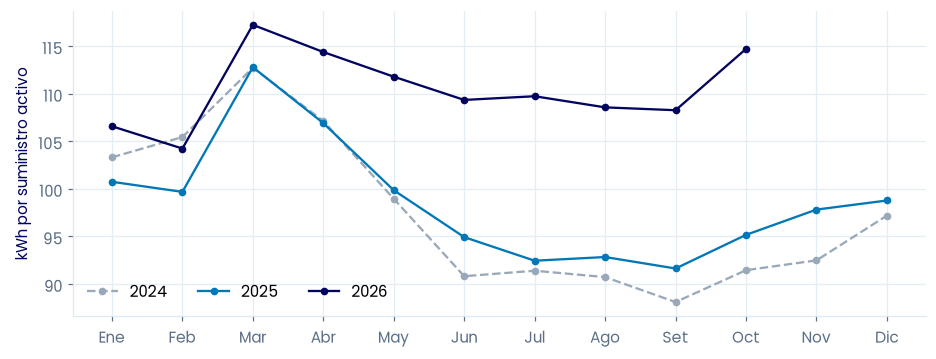

In [8]:
sr = panel.assign(kwh=panel["y"] * panel["n_act"]).groupby("PERIODO")[["kwh", "n_act"]].sum()
media = sr["kwh"] / sr["n_act"]
fig, ax = plt.subplots()
for anio, col, ls in (("2024", GRIS, "--"), ("2025", BLUE, "-"), ("2026", NAVY, "-")):
    m = media[media.index.str.startswith(anio)]
    ax.plot(
        [int(p[4:]) - 1 for p in m.index], m.values, color=col, ls=ls, marker="o", ms=4, label=anio
    )
ax.set_xticks(range(12), MESES)
ax.set_ylabel("kWh por suministro activo")
ax.legend(ncol=3)
plt.show()

El consumo medio regional tiene su máximo en marzo (verano) y, en 2026, fue mayor que en el mismo mes de 2025 en todos los meses. Este cambio de nivel explica más adelante por qué la corrida 1 no supera al pronóstico ingenuo.

<a id="variables-de-entrada-y-formulaciones"></a>

## 8. Variables de entrada y formulaciones

A partir del panel se construyen los rezagos de cada distrito. Hay dos formulaciones del objetivo:

- **Corrida 1 (nivel):** se pronostica $y_t$ con $y_{t-1}, y_{t-2}, y_{t-12}$, los días facturados, el logaritmo del número de suministros y la proporción de recibos en cero del mes anterior.
- **Corrida 2 (variación):** se pronostica $\Delta_t = \ln(y_t / y_{t-1})$ con $\Delta_{t-1}$, $\Delta_{t-12}$ y la razón de días facturados; el consumo se recupera como $\hat y_t = y_{t-1}\,e^{\hat\Delta_t}$.

En ambas, el mes, la provincia y el grupo de k-means son variables categóricas. Como $\Delta_{t-12}$ necesita el consumo de 13 meses antes, las filas supervisadas empiezan en febrero de 2025.

In [9]:
from ml import caracteristicas as car

pn = car.agregar_rezagos(
    car.ordenar(panel).assign(grupo=0)
)  # el grupo real se añade en el notebook 3
sup_ = car.supervisado(pn)
print(f"Filas supervisadas: {len(sup_)} ({sup_['PERIODO'].min()} a {sup_['PERIODO'].max()})")
print("Corrida 1:", car.entradas(1), "→", car.objetivo(1))
print("Corrida 2:", car.entradas(2), "→", car.objetivo(2))
sup_[sup_["UBIGEO"] == "200101"][
    ["PERIODO", "y", "lag1", "lag12", "dl", "dl_prev", "dl_seas", "dias_ratio"]
].head()

Filas supervisadas: 1638 (202502 a 202610)
Corrida 1: ['lag1', 'lag2', 'lag12', 'dias', 'log_n', 'p_cero_lag1', 'mes', 'PROV_N', 'grupo'] → y
Corrida 2: ['dl_prev', 'dl_seas', 'dias_ratio', 'log_n', 'p_cero_lag1', 'mes', 'PROV_N', 'grupo'] → dl


,PERIODO,y,lag1,lag12,dl,dl_prev,dl_seas,dias_ratio
0,202502,161.8012,159.3557,173.9723,0.0152,0.0386,0.0549,0.9159
1,202503,192.2638,161.8012,189.7224,0.1725,0.0152,0.0867,1.1313
2,202504,180.6355,192.2638,178.4769,-0.0624,0.1725,-0.0611,0.9616
3,202505,159.7232,180.6355,162.8210,-0.1230,-0.0624,-0.0918,0.9951
4,202506,155.6339,159.7232,147.2278,-0.0259,-0.1230,-0.1007,1.0057


<a id="verificación-con-el-informe"></a>

## 9. Verificación con el informe

El panel y los conteos obtenidos aquí deben coincidir exactamente con los archivos publicados en el repositorio, que son los del informe.

In [10]:
pd.testing.assert_frame_equal(
    panel.reset_index(drop=True), pd.read_parquet(config.PANEL).reset_index(drop=True)
)
for clave in (
    "filas_totales",
    "residenciales_bt5b",
    "atipicos_sup",
    "atipicos_inf",
    "activos_limpios",
    "celdas_total",
):
    assert resumen[clave] == RESUMEN[clave], clave
print("El panel y los conteos coinciden con los publicados.")

El panel y los conteos coinciden con los publicados.


<a id="conclusiones"></a>

## 10. Conclusiones

- Los 19,7 millones de registros se reducen a **17 766 272 recibos activos limpios** de hogares BT5B y se agregan en un panel completo de **78 distritos × 34 meses** (2652 filas), sin usar ninguna columna personal.
- El consumo tiene cola larga y muchos ceros; las cercas de Tukey sobre el logaritmo eliminan solo valores extremos.
- La serie regional es estacional (máximo en marzo) y en 2026 cambió de nivel, lo que motiva la segunda formulación, basada en la variación mensual.

El panel resultante es la entrada de los notebooks 2 (no supervisado) y 3 (supervisado).

<a id="referencias"></a>

## 11. Referencias

- Congreso de la República del Perú. (2011, 3 de julio). *Ley N.° 29733, Ley de Protección de Datos Personales*. Diario Oficial El Peruano. https://diariooficial.elperuano.pe/Normas/obtenerDocumento?idNorma=23
- Empresa Regional de Servicio Público de Electricidad Electronoroeste S.A. - ENOSA. (2026). *Consumo energético de clientes Enosa [Distriluz - DLZ]* [Conjunto de datos]. Plataforma Nacional de Datos Abiertos. Recuperado el 20 de noviembre de 2026, de https://www.datosabiertos.gob.pe/dataset/consumo-energ%C3%A9tico-de-clientes-enosa-distriluz-dlz
- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.